# Mapping Henry Ice Rise
Loads a plots:
- MODIS mosaic of Antarctica (MOA) data
- bedmap2 digitical elevation model
- Reference elevation model of Antarctica (REMA) data
- a vector dataset of all the radar lines on HIR
- a vector of just a line corresponding to the radargram in a different plot (HEnorth_FL5)
- proposed drill site, 
- and worldview imagery of HIR. 


In [ ]:
# Imports for the geospatial workflow to come.
import rioxarray  
import geopandas as gpd
import matplotlib.pyplot as plt
import pdemtools as pdt
import geopandas as gpd

from matplotlib.patches import Rectangle


### Whole-HIR bedmap-2DEM

In [2]:
wide_bounds = [-1075132.7702415055,385691.92500027467,-814001.8660672065,576698.6831667994]

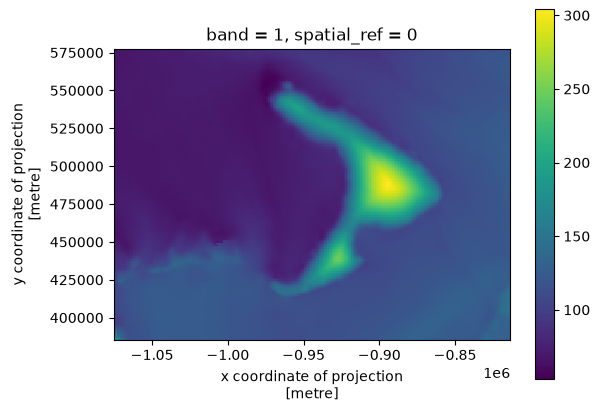

In [3]:
bm2_surf = rioxarray.open_rasterio('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/TerrainModels/BEDMAP2/bedmap2_surface.tif', chunked=True).rio.clip_box(*wide_bounds)
bm2_thickness = rioxarray.open_rasterio('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/TerrainModels/BEDMAP2/bedmap2_thickness.tif', chunked=True).rio.clip_box(*wide_bounds)
bm2_surf.plot()
plt.gca().set_aspect('equal') 

### MODIS Mosaic of Antarctica (MOA)
obtained from quantarcitca: 
/Users/jkingslake/Documents/science/QGIS/Quantarctica3/SatelliteImagery/MODIS/MODIS_Mosaic.tif  

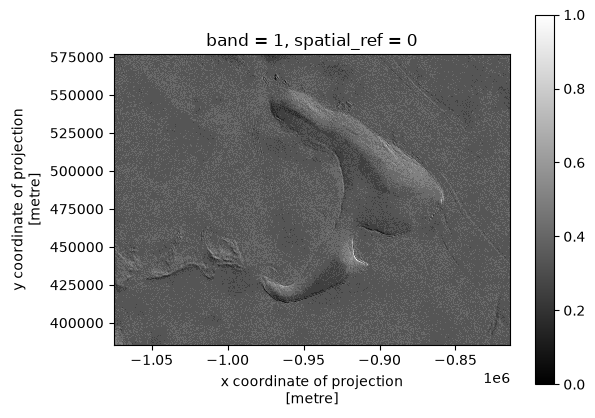

In [4]:
moa = rioxarray.open_rasterio('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/SatelliteImagery/MODIS/MODIS_Mosaic.tif', chunked=True).rio.clip_box(*wide_bounds)
min_val = moa.min()
max_val = moa.max()
moa_norm = (moa - min_val) / (max_val - min_val)
moa_norm.plot(cmap = 'gray')

plt.gca().set_aspect('equal') 

In [5]:
bounds = [-1075132.7702415055,385691.92500027467,-814001.8660672065,576698.6831667994]

In [6]:
close_bounds = [-1002656.0978736078,507610.546840948,-914375.0208685583,572184.6055089663] # closer

## Reference Elevation Model of Antarctica (REMA)

In [7]:
dem = pdt.load.mosaic(
    dataset='rema',  # must be `arcticdem` or `rema`
    resolution=32,        # must be 2, 10, or 32
    bounds=close_bounds,        # (xmin, ymin, xmax, ymax) or a shapely geometry
)

In [ ]:
dem = dem.coarsen(x=4, y=4, boundary='trim').mean()  

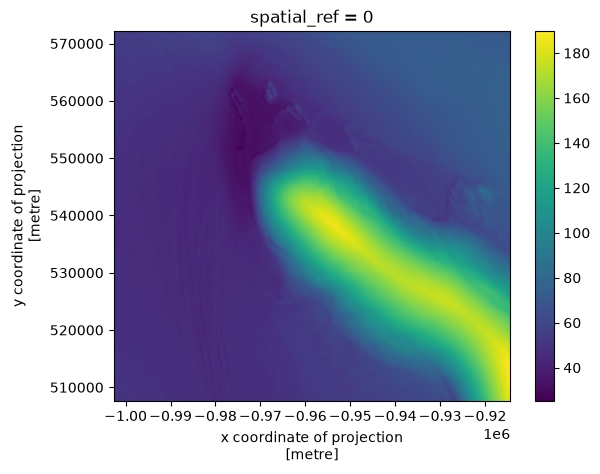

In [9]:
dem.plot()

## MOA again, but closer

In [10]:
moa_close = rioxarray.open_rasterio('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/SatelliteImagery/MODIS/MODIS_Mosaic.tif', chunked=True).rio.clip_box(*close_bounds)
min_val = moa_close.min()
max_val = moa_close.max()
moa_norm_close = (moa_close - min_val) / (max_val - min_val)

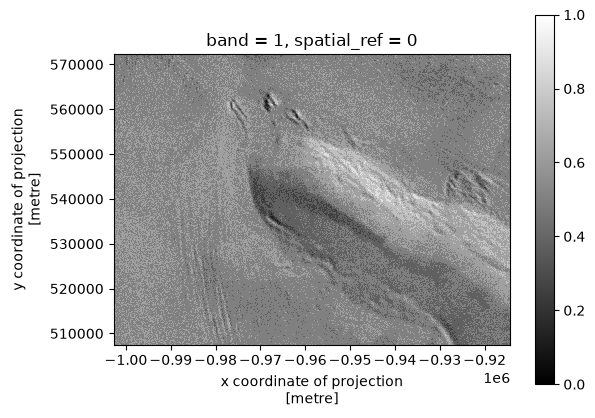

In [11]:
moa_norm_close.plot(cmap = 'gray')

plt.gca().set_aspect('equal') 

## Radar line position data

In [ ]:
HEnorth_FL5_gdf = gpd.read_file('HEnorth_FL5_gdf.geojson')
drillsite_gdf = gpd.read_file('drillsite_gdf.geojson')

## REMA hillshape plot with radarline

In [ ]:
hillshade = dem.pdt.terrain('hillshade')

<Axes: title={'center': 'spatial_ref = 0'}, xlabel='x coordinate of projection\n[metre]', ylabel='y coordinate of projection\n[metre]'>

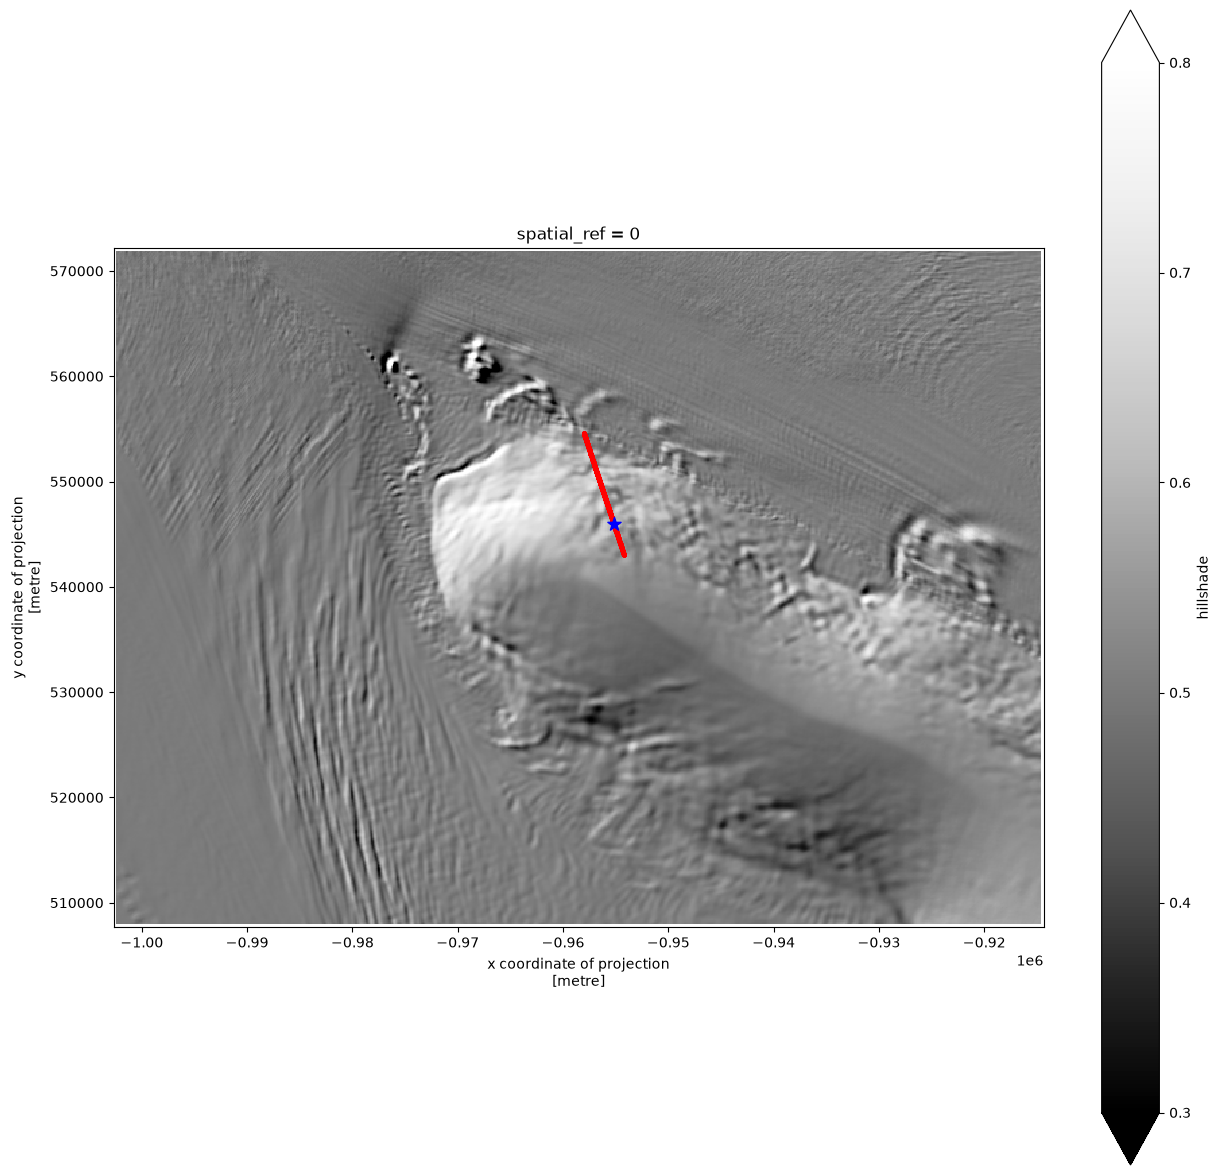

In [14]:
fig, ax = plt.subplots(figsize=(15, 15))

hillshade.plot(ax=ax,cmap='Greys_r', vmin=0.3, vmax = 0.8)
HEnorth_FL5_gdf.plot(ax=ax, color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax, marker = '*', markersize=100, color='blue', label='Drill Site')

## Mean curvature with radarline

<Axes: title={'center': 'spatial_ref = 0'}, xlabel='x coordinate of projection\n[metre]', ylabel='y coordinate of projection\n[metre]'>

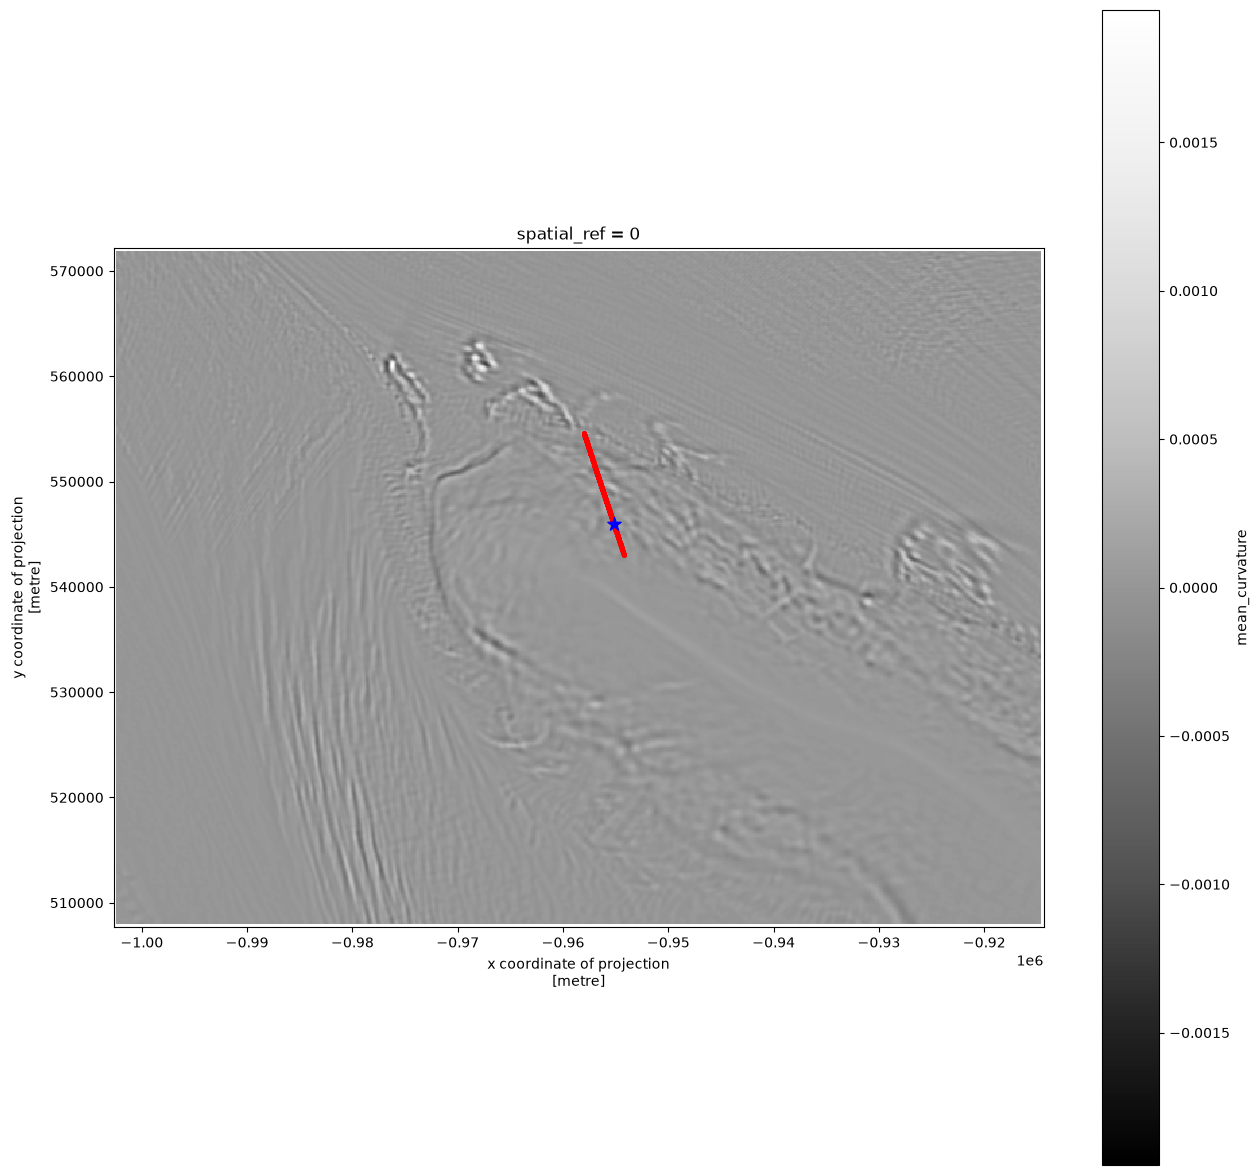

In [15]:
fig, ax = plt.subplots(figsize=(15, 15))
dem.pdt.terrain('mean_curvature', ).plot(ax=ax,cmap='Greys_r')
HEnorth_FL5_gdf.plot(ax=ax, color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax, marker = '*', markersize=100, color='blue', label='Drill Site')

## Load all DELORES radar line locations

In [16]:
all_del_positions = gpd.read_file('/Users/jkingslake/Documents/data/ronne_fieldwork/python_processing/delores_GPS_singleBand_both_seasons.gpkg')

In [17]:
all_del_positions_small = all_del_positions.iloc[::20].reset_index(drop=True)


In [18]:
all_del_positions_small = all_del_positions_small.to_crs('EPSG:3031')
all_del_positions_small

,lat,lon,geometry
0,-80.648548,-61.225158,POINT (-892495.682 490143.445)
1,-80.648550,-61.225162,POINT (-892495.552 490143.305)
2,-80.648548,-61.225164,POINT (-892495.731 490143.357)
3,-80.648550,-61.225167,POINT (-892495.595 490143.227)
4,-80.648550,-61.225168,POINT (-892495.609 490143.201)
...,...,...,...
78206,-79.947457,-60.420968,POINT (-952234.45 540483.605)
78207,-79.947457,-60.420968,POINT (-952234.45 540483.605)
78208,-79.947457,-60.420968,POINT (-952234.45 540483.605)
78209,-79.947457,-60.420968,POINT (-952234.45 540483.605)


Subset all DELORES line position data to be near the proposed drill site

In [20]:
ref_point = drillsite_gdf.geometry.iloc[0]
all_del_positions_small["dist_m"] = all_del_positions_small.distance(ref_point)
all_del_positions_near = all_del_positions_small[all_del_positions_small["dist_m"] < 60000]
all_del_positions_near

,lat,lon,geometry,dist_m
610,-80.178622,-61.550633,POINT (-940461.348 509553.252),39299.578585
611,-80.178623,-61.550633,POINT (-940461.189 509553.166),39299.717824
612,-80.178622,-61.550633,POINT (-940461.348 509553.252),39299.578585
613,-80.178622,-61.550633,POINT (-940461.348 509553.252),39299.578585
614,-80.178622,-61.550635,POINT (-940461.363 509553.224),39299.599145
...,...,...,...,...
78206,-79.947457,-60.420968,POINT (-952234.45 540483.605),6248.260244
78207,-79.947457,-60.420968,POINT (-952234.45 540483.605),6248.260244
78208,-79.947457,-60.420968,POINT (-952234.45 540483.605),6248.260244
78209,-79.947457,-60.420968,POINT (-952234.45 540483.605),6248.260244


## Load grounding line data from quantarctica

<Axes: >

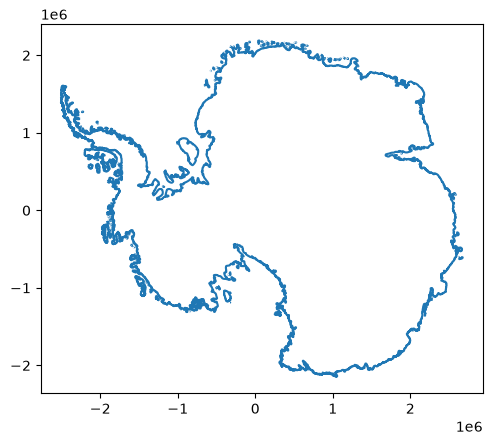

In [ ]:
gl = gpd.read_file('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/Glaciology/MEaSUREs Antarctic Boundaries/GroundingLine_Antarctica_v2.shp')
gl.boundary.plot()

## MOA with all DELORES lines + the one line displayed in a radargram + grounding line
Used in Figure 3a of proposal

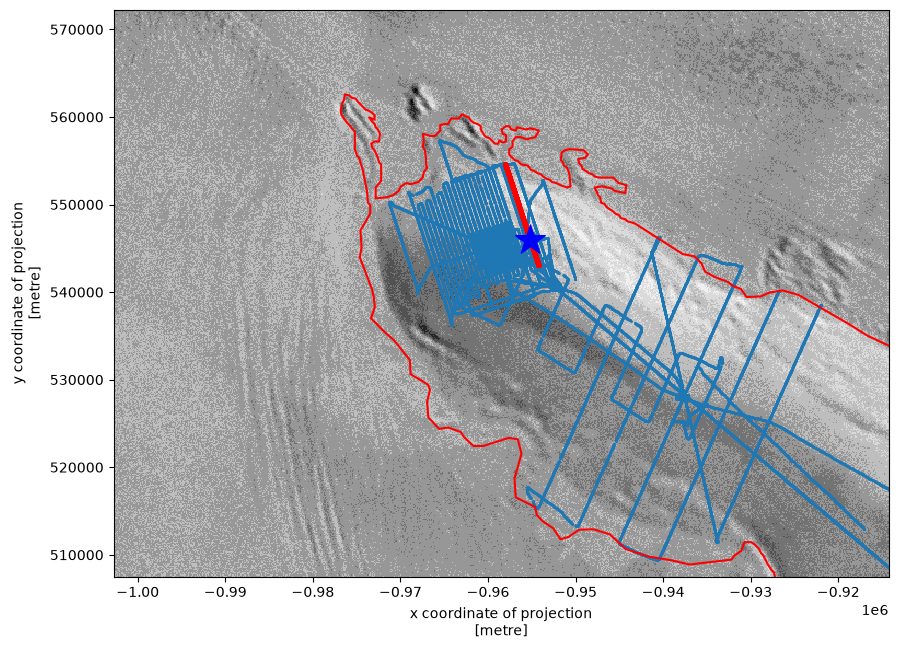

In [22]:
fig, ax = plt.subplots(figsize=(10, 10))
moa_close.plot(ax=ax,cmap='Greys_r', add_colorbar = False)
gl.boundary.plot(ax=ax, color='red', label = 'grounding line')

all_del_positions_near.plot(ax=ax, markersize=1,)
HEnorth_FL5_gdf.plot(ax=ax, color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax, marker = '*', markersize=500, color='blue', label='Drill Site')
ax.set_title('')

plt.savefig('radarline_location_map.png', dpi = 300, bbox_inches='tight'  )

Different variant with a normalized MOA

<Axes: title={'center': 'band = 1, spatial_ref = 0'}, xlabel='x coordinate of projection\n[metre]', ylabel='y coordinate of projection\n[metre]'>

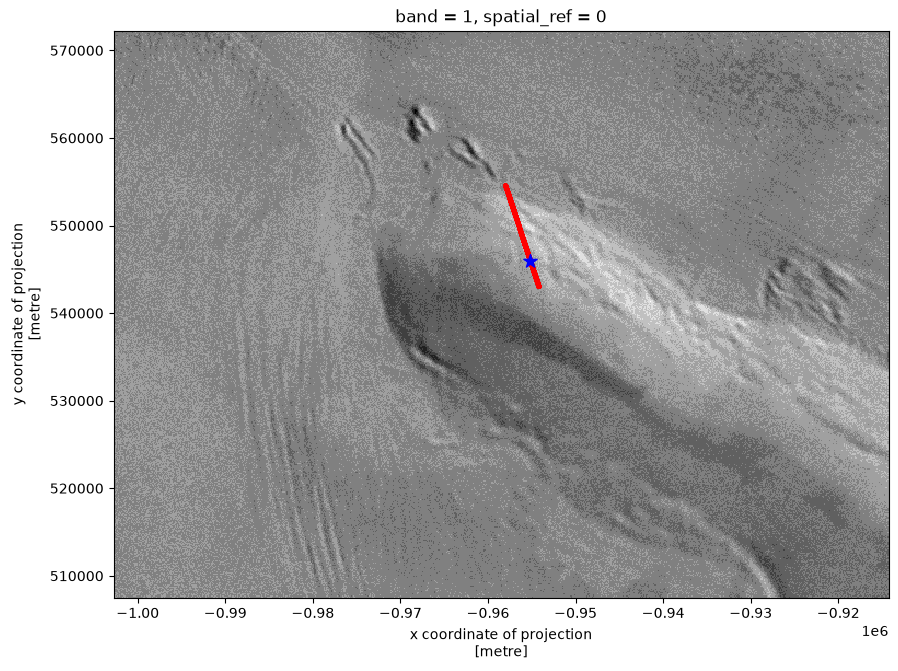

In [23]:
fig, ax = plt.subplots(figsize=(10, 10))
moa_norm_close.plot(ax=ax, cmap = 'gray',add_colorbar=False)
HEnorth_FL5_gdf.plot(ax=ax, color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax, marker = '*', markersize=100, color='blue', label='Drill Site')

## Worldview imagery
First a subset in a crevassed region near the grounding line (location chosen by browsing the image in QGIS)

In [24]:
width = 1000
height = 1000
xmin = -951368
xmax = xmin + width
ymin = 551293
ymax = ymin + height
crevasses_bounds = [xmin, ymin, xmax, ymax]
WV_crevasses= rioxarray.open_rasterio('/Users/jkingslake/Documents/projects/proposals/other/PHIRE/proposal/fridge_1479_jkingslake/ortho/WV01_20250228140506_102001010D9E6800_25FEB28140506-P1BS-509390623020_01_P007_u08rf3031.tif', chunks = True, masked = True)\
    .rio.clip_box(*crevasses_bounds)

Then the whole 'close' region (the bounds we used for the REMA and MOA plots). Also coarsen because we dont need the full resolution at this scale.

In [25]:
WV_close = rioxarray.open_rasterio('/Users/jkingslake/Documents/projects/proposals/other/PHIRE/proposal/fridge_1479_jkingslake/ortho/WV01_20250228140506_102001010D9E6800_25FEB28140506-P1BS-509390623020_01_P007_u08rf3031.tif', chunks = True, masked = True)\
    .rio.clip_box(*close_bounds).coarsen(x=20, y=20, boundary = 'trim').mean().compute()

Then a a subset around the proposal drill site.

In [26]:
drillsite_x = drillsite_gdf.get_geometry(0).x.values[0]
drillsite_y = drillsite_gdf.get_geometry(0).y.values[0]
width = 1000
height = 1000
xmin = -951368
xmax = xmin + width
ymin = 551293
ymax = ymin + height
drillsite_bounds = [drillsite_x-width/2, drillsite_y-height/2, drillsite_x+width/2, drillsite_y+height/2]
WV_drillsite = rioxarray.open_rasterio('/Users/jkingslake/Documents/projects/proposals/other/PHIRE/proposal/fridge_1479_jkingslake/ortho/WV01_20250228140506_102001010D9E6800_25FEB28140506-P1BS-509390623020_01_P007_u08rf3031.tif', chunks = True, masked = True)\
    .rio.clip_box(*drillsite_bounds)


## The full (coarsened) WV image and the two close zooms + GL + radar lines + proposed drill site.

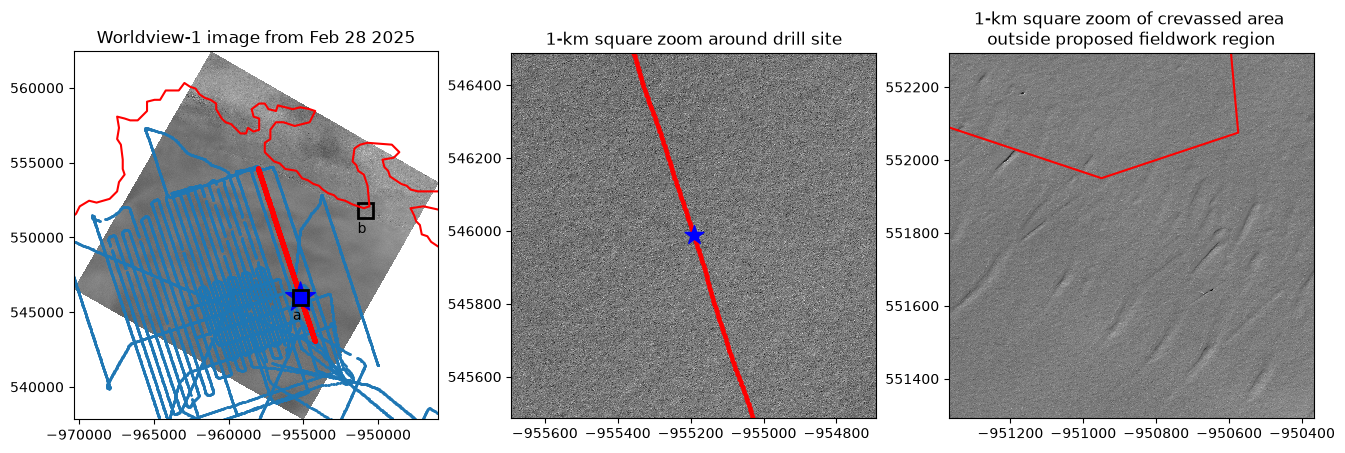

In [44]:
fig, ax = plt.subplots(1,3, figsize = (16, 8),)
WV_close.plot(ax=ax[0], cmap = 'gray', add_colorbar=False)
gl.boundary.plot(ax=ax[0], color='red', label = 'grounding line')

all_del_positions_near.plot(ax=ax[0], markersize=1,)
HEnorth_FL5_gdf.plot(ax=ax[0], color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax[0], marker = '*', markersize=500, color='blue', label='Drill Site')
# HEnorth_FL5_gdf.plot(ax=ax[0], color='red', markersize=5, label='radar line')
# drillsite_gdf.plot(ax=ax[0], marker = '*', markersize=200, color='blue', label='Drill Site')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
# gl.boundary.plot(ax=ax[0], color='red', label = 'grounding line')

ax[0].text(drillsite_bounds[0], drillsite_bounds[1]-1000, 'a')
ax[0].text(crevasses_bounds[0], crevasses_bounds[1]-1000, 'b')

rect1 = Rectangle(
    (drillsite_bounds[0], drillsite_bounds[1]),      # bottom-left corner, in data coordinates (distance, z)
    width,     # extent along x
    height,     # extent along y
    linewidth=2,
    edgecolor="black",
    facecolor="none",
)
ax[0].add_patch(rect1)

rect2 = Rectangle(
    (crevasses_bounds[0], crevasses_bounds[1]),      # bottom-left corner, in data coordinates (distance, z)
    width,     # extent along x
    height,     # extent along y
    linewidth=2,
    edgecolor="black",
    facecolor="none",
)
ax[0].add_patch(rect2)
ax[0].set_title('Worldview-1 image from Feb 28 2025')
# ax[0].legend()


WV_drillsite.plot(ax=ax[1], cmap = 'gray', add_colorbar=False)
HEnorth_FL5_gdf.plot(ax=ax[1], color='red', markersize=5, label='radar line')
drillsite_gdf.plot(ax=ax[1], marker = '*', markersize=200, color='blue', label='Drill Site')
ax[1].set_ylabel('')
ax[1].set_xlabel('')
ax[1].set_title('1-km square zoom around drill site')


WV_crevasses.plot(ax=ax[2], cmap = 'gray', add_colorbar=False)
HEnorth_FL5_gdf.plot(ax=ax[2], color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax[2], marker = '*', markersize=100, color='blue', label='Drill Site')
ax[2].set_ylabel('')
ax[2].set_xlabel('')
ax[2].set_title('1-km square zoom of crevassed area \n outside proposed fieldwork region ')
gl.boundary.plot(ax=ax[2], color='red', label = 'grounding line')

plt.savefig('worldview_crevasse_imagery_1.png', dpi = 300, bbox_inches='tight'  )
